In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.5 MB/s eta 0:00:00


### 학습

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
재활용품 YOLO 학습 시작
클래스: {0: 'plastic', 1: 'pet', 2: 'glass', 3: 'can', 4: 'paper', 5: 'vinyl'}
Epoch: 100
Batch Size: 32
Learning Rate: 0.001
Patience: 15
Output: /content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/outputs
GPU 사용: Tesla T4
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/config/config_recycle

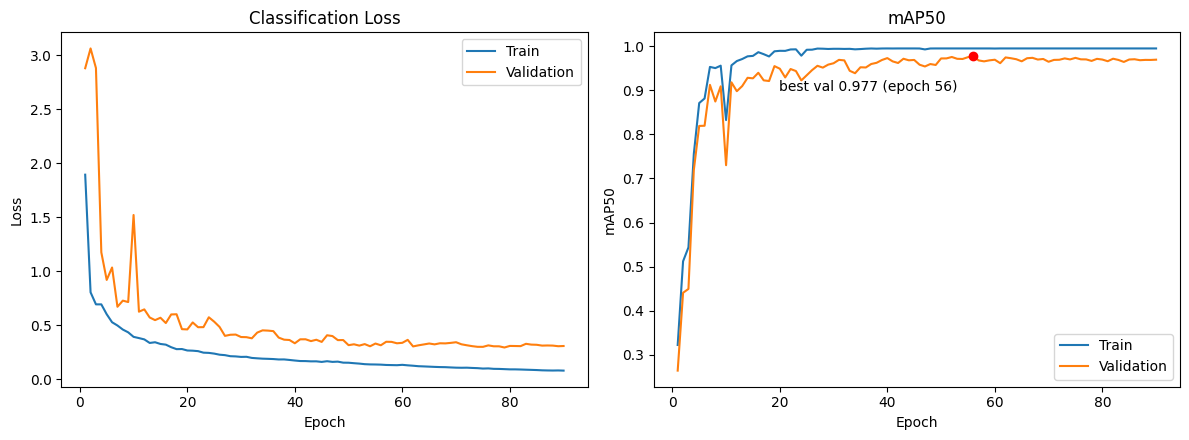

✅ 학습 곡선 저장: /content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/outputs/recycle_yolo/results.png

🧪 YOLO 모델 검증 시작
📌 대상: 966개


분석 중:   0%|          | 0/31 [00:00<?, ?it/s]


📌 분류 정확도 (찾아낸 물체 기준): 0.9744
📌 검출률 (Recall): 0.9877  (1287/1303)
📌 오탐 개수 (False Positive): 42

📋 Classification Report
              precision    recall  f1-score   support

     plastic       0.99      0.97      0.98       218
         pet       0.96      0.98      0.97       215
       glass       0.97      0.97      0.97       214
         can       0.91      0.97      0.94       216
       paper       0.96      0.94      0.95       226
       vinyl       0.87      0.95      0.91       214

   micro avg       0.94      0.96      0.95      1303
   macro avg       0.94      0.96      0.95      1303
weighted avg       0.95      0.96      0.95      1303



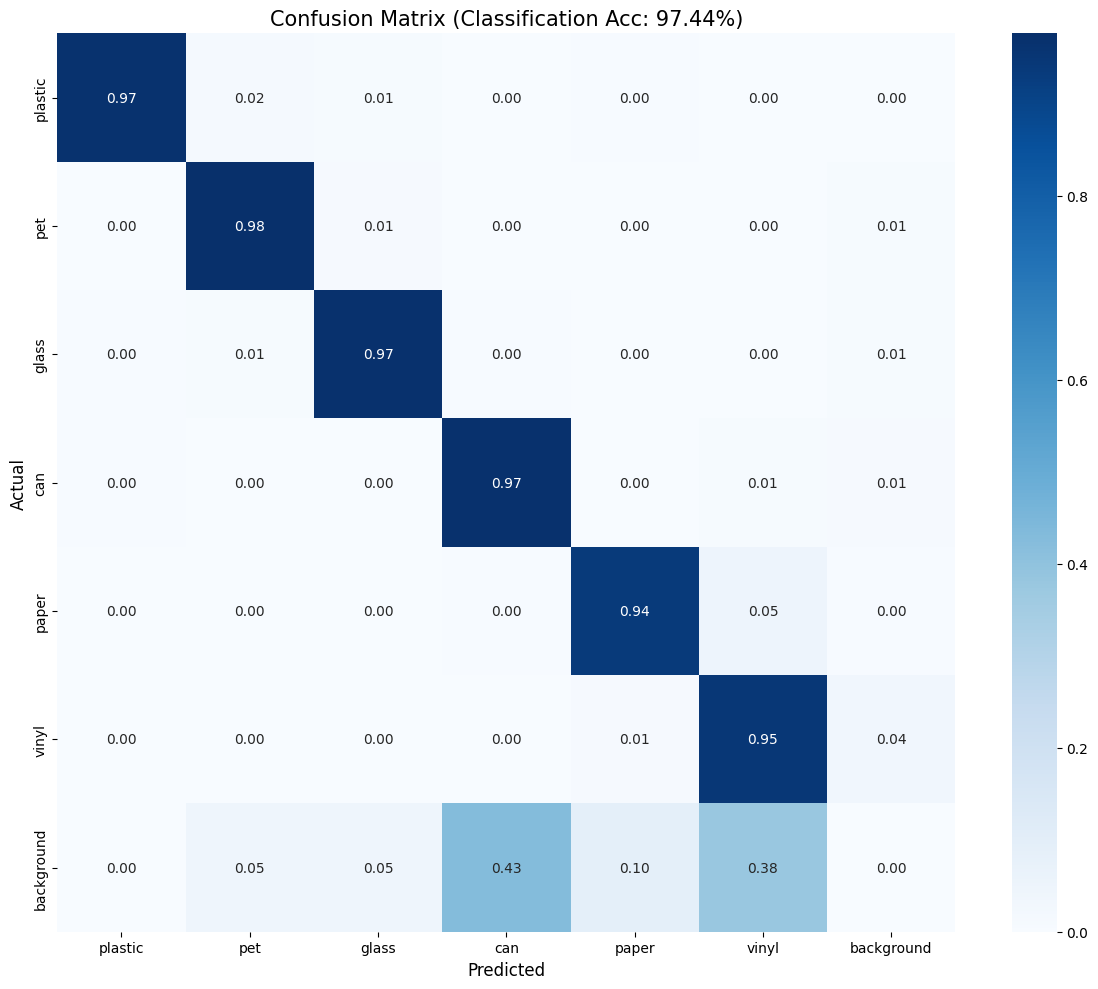


✨ 저장 완료
/content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/outputs/confusion/confusion_matrix.png


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7cf1e6573930>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

In [3]:
import sys
import os
import importlib

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "뚝딱뚝딱/model(YOLO)"
)

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

SRC_PATH = os.path.join(
    PROJECT_ROOT,
    "src"
)

if SRC_PATH not in sys.path:
    sys.path.append(SRC_PATH)
os.chdir(PROJECT_ROOT)

from src.train import run_process

CONFIG_PATH = os.path.join(
    PROJECT_ROOT,
    "config",
    "config_recycle.yaml"
)

run_process(CONFIG_PATH)

## config.yaml

In [ ]:
import yaml
import os

BASE = "/content/drive/MyDrive/뚝딱뚝딱/model(YOLO)"
config_path = f"{BASE}/config/config_recycle.yaml"
os.makedirs(os.path.dirname(config_path), exist_ok=True)

config_data = {
    "data_root": f"{BASE}/datasets",
    "cache_path": f"{BASE}/cache",
    "output_path": f"{BASE}/outputs",
    "names": {
        0: "plastic",
        1: "pet",
        2: "glass",
        3: "can",
        4: "paper",
        5: "vinyl"
    },

    # Roboflow 라벨링한 캐시
    "extra_caches": ["vinyl_label", "paper_label", "glass_cap", "cup_holder", "box"],

    # 수가 적은 캐시는 train에서만 반복 (val/test는 1번)
    "repeat": {"cup_holder": 5, "box": 3},

    # 학습 설정
    "seed": 42,
    "epochs": 100,
    "batch_size": 32,
    "learning_rate": 0.001,
    "patience": 15,
    "target_count": 500
}

with open(config_path, "w", encoding="utf-8") as f:
    yaml.dump(config_data, f, sort_keys=False, allow_unicode=True)

print(f"✅ YAML updated at: {config_path}")
print(f"📁 데이터셋 경로: {config_data['data_root']}")
print(f"📁 캐시 폴더 경로: {config_data['cache_path']}")

✅ YAML updated at: /content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/config/config_recycle.yaml
📁 데이터셋 경로: /content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/datasets
📁 캐시 폴더 경로: /content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/cache


### 캐싱

In [ ]:
import sys
import os

PROJECT_ROOT = (
    "/content/drive/MyDrive/"
    "뚝딱뚝딱/model(YOLO)"
)

SRC_PATH = os.path.join(PROJECT_ROOT, "src")

if SRC_PATH not in sys.path:
    sys.path.append(SRC_PATH)

os.chdir(PROJECT_ROOT)

from cache import load_config, build_class_cache, build_coco_cache

config = load_config()
data_root = config["data_root"]
cache_path = config["cache_path"]


def cache_exists(name):
    return os.path.exists(os.path.join(cache_path, f"{name}.pt"))


# 1) AI Hub 클래스별 캐시 (6개)
for class_name in config["names"].values():

    if cache_exists(class_name):
        print(f"⏭️ {class_name}.pt 이미 있음 → 건너뜀")
        continue

    build_class_cache(class_name)


# 2) Roboflow 라벨링 캐시 (3개)
for name in config.get("extra_caches", []):

    if cache_exists(name):
        print(f"⏭️ {name}.pt 이미 있음 → 건너뜀")
        continue

    build_coco_cache(
        name,
        image_dir=os.path.join(data_root, f"s_{name}"),
        coco_path=os.path.join(data_root, f"s_{name}.json"),
    )

print("\n✅ 캐싱 완료")
print("cache 폴더:", sorted(f for f in os.listdir(cache_path) if f.endswith(".pt")))

⏭️ plastic.pt 이미 있음 → 건너뜀
⏭️ pet.pt 이미 있음 → 건너뜀
⏭️ glass.pt 이미 있음 → 건너뜀
⏭️ can.pt 이미 있음 → 건너뜀
⏭️ paper.pt 이미 있음 → 건너뜀
⏭️ vinyl.pt 이미 있음 → 건너뜀
⏭️ vinyl_label.pt 이미 있음 → 건너뜀
⏭️ paper_label.pt 이미 있음 → 건너뜀
⏭️ glass_cap.pt 이미 있음 → 건너뜀
⏭️ cup_holder.pt 이미 있음 → 건너뜀
카테고리 매칭: {'hardwareBox': None, 'can': 3, 'glass': 2, 'paper': 4, 'pet': 1, 'plastic': 0, 'vinyl': 5}


box 캐싱:   0%|          | 0/200 [00:00<?, ?장/s]

✅ box.pt 저장 완료
   데이터 수: 200 / 200  (용량 4.7MB)
   박스 분포: {'plastic': 40, 'paper': 30, 'pet': 70, 'vinyl': 50, 'can': 70, 'glass': 70}
   경계 밖이라 잘라낸 박스: 1
   위치: /content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/cache/box.pt

✅ 캐싱 완료
cache 폴더: ['box.pt', 'can.pt', 'cup_holder.pt', 'glass.pt', 'glass_cap.pt', 'paper.pt', 'paper_label.pt', 'pet.pt', 'plastic.pt', 'vinyl.pt', 'vinyl_label.pt']


### 데이터 파악

In [ ]:
import os

base_path = "/content/drive/MyDrive/뚝딱뚝딱/model(YOLO)/datasets"

folders = [
    "s_vinyl",
    "s_paper",
    "s_plastic",
    # "s_clear_plastic",
    "s_can",
    "s_glass",
    # "s_can_2",
    # "s_clear_plastic2",
    "l_vinyl",
    "l_paper",
    "l_plastic",
    "l_glass",
    "l_can",
    "s_vinyl_label",
    "s_paper_label",
    "s_glass_cap"

]

for folder in folders:
    folder_path = os.path.join(base_path, folder)

    jpg_count = 0

    for file in os.listdir(folder_path):
        if file.lower().endswith((".jpg",".json")):
            jpg_count += 1

    print(f"{folder}: {jpg_count}개")

s_vinyl: 500개
s_paper: 500개
s_plastic: 500개
s_can: 500개
s_glass: 500개
l_vinyl: 500개
l_paper: 500개
l_plastic: 500개
l_glass: 500개
l_can: 500개
s_vinyl_label: 500개
s_paper_label: 500개
s_glass_cap: 500개
